# Loan Recovery Prediction Using Machine Learning

## Project Objective

Build classification models to predict the likelihood of loan recovery,
evaluate model performance using Recall and ROC-AUC metrics, and provide
explainable insights to support optimized debt recovery strategies.

## 1. Data Import

The raw loan recovery dataset is loaded and checked before cleaning.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv("../data/loan_recovery_dataset_25000_raw.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df

,customer_id,customer_name,loan_id,age,income,employment_type,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income,existing_loans,previous_defaults,payment_delays,employment_years,collateral_value,loan_purpose,contact_success_rate,loan_recovered
0,CUST006869,Ishaan Kapoor,LN0006869,50,94000.0,Salaried,641.0,480000.0,48,7.84,0.302,1,0.0,0.0,14,355000.0,Vehicle,0.688,1
1,CUST024017,Akash Mirza,LN0024017,40,61000.0,Salaried,545.0,155000.0,48,11.51,0.206,0,1.0,2.0,6,5000.0,Personal,0.400,1
2,CUST009669,Naveen Mishra,LN0009669,60,141500.0,Salaried,740.0,1075000.0,18,8.10,0.190,0,0.0,0.0,28,595000.0,Vehicle,0.903,1
3,CUST013641,Imran Saxena,LN0013641,37,48500.0,Self-employed,602.0,195000.0,18,9.33,0.275,2,0.0,0.0,2,135000.0,Vehicle,0.486,0
4,CUST014019,Dev Gowda,LN0014019,31,45000.0,Salaried,669.0,220000.0,60,9.99,0.280,2,0.0,1.0,8,25000.0,Personal,0.506,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,CUST021576,Rehan Pawar,LN0021576,25,39500.0,Salaried,618.0,385000.0,60,9.80,0.209,1,1.0,0.0,5,370000.0,Business,0.383,0
24996,CUST005391,Abhinav Hegde,LN0005391,40,77500.0,Contract,663.0,485000.0,48,9.58,0.209,1,0.0,1.0,10,65000.0,Personal,0.502,1
24997,CUST000861,Amit Patil,LN0000861,37,77000.0,NaN,579.0,1105000.0,72,9.63,0.172,0,2.0,4.0,7,1395000.0,Home,0.310,0
24998,CUST015796,Harini Kapoor,LN0015796,38,84500.0,Salaried,558.0,610000.0,12,10.18,0.307,3,4.0,5.0,12,55000.0,Education,0.138,0


In [6]:
df.head()

,customer_id,customer_name,loan_id,age,income,employment_type,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income,existing_loans,previous_defaults,payment_delays,employment_years,collateral_value,loan_purpose,contact_success_rate,loan_recovered
0,CUST006869,Ishaan Kapoor,LN0006869,50,94000.0,Salaried,641.0,480000.0,48,7.84,0.302,1,0.0,0.0,14,355000.0,Vehicle,0.688,1
1,CUST024017,Akash Mirza,LN0024017,40,61000.0,Salaried,545.0,155000.0,48,11.51,0.206,0,1.0,2.0,6,5000.0,Personal,0.400,1
2,CUST009669,Naveen Mishra,LN0009669,60,141500.0,Salaried,740.0,1075000.0,18,8.10,0.190,0,0.0,0.0,28,595000.0,Vehicle,0.903,1
3,CUST013641,Imran Saxena,LN0013641,37,48500.0,Self-employed,602.0,195000.0,18,9.33,0.275,2,0.0,0.0,2,135000.0,Vehicle,0.486,0
4,CUST014019,Dev Gowda,LN0014019,31,45000.0,Salaried,669.0,220000.0,60,9.99,0.280,2,0.0,1.0,8,25000.0,Personal,0.506,1


In [7]:
df.tail()

,customer_id,customer_name,loan_id,age,income,employment_type,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income,existing_loans,previous_defaults,payment_delays,employment_years,collateral_value,loan_purpose,contact_success_rate,loan_recovered
24995,CUST021576,Rehan Pawar,LN0021576,25,39500.0,Salaried,618.0,385000.0,60,9.80,0.209,1,1.0,0.0,5,370000.0,Business,0.383,0
24996,CUST005391,Abhinav Hegde,LN0005391,40,77500.0,Contract,663.0,485000.0,48,9.58,0.209,1,0.0,1.0,10,65000.0,Personal,0.502,1
24997,CUST000861,Amit Patil,LN0000861,37,77000.0,NaN,579.0,1105000.0,72,9.63,0.172,0,2.0,4.0,7,1395000.0,Home,0.310,0
24998,CUST015796,Harini Kapoor,LN0015796,38,84500.0,Salaried,558.0,610000.0,12,10.18,0.307,3,4.0,5.0,12,55000.0,Education,0.138,0
24999,CUST023655,Ananya Desai,LN0023655,36,70500.0,Salaried,694.0,365000.0,36,8.99,0.191,1,0.0,0.0,5,80000.0,Personal,0.639,1


In [8]:
df.shape

(25000, 19)

In [9]:
df.columns

Index(['customer_id', 'customer_name', 'loan_id', 'age', 'income',
       'employment_type', 'credit_score', 'loan_amount', 'loan_term_months',
       'interest_rate', 'debt_to_income', 'existing_loans',
       'previous_defaults', 'payment_delays', 'employment_years',
       'collateral_value', 'loan_purpose', 'contact_success_rate',
       'loan_recovered'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           25000 non-null  object 
 1   customer_name         25000 non-null  object 
 2   loan_id               25000 non-null  object 
 3   age                   25000 non-null  int64  
 4   income                24550 non-null  float64
 5   employment_type       24696 non-null  object 
 6   credit_score          24626 non-null  float64
 7   loan_amount           24750 non-null  float64
 8   loan_term_months      25000 non-null  int64  
 9   interest_rate         25000 non-null  float64
 10  debt_to_income        24552 non-null  float64
 11  existing_loans        25000 non-null  int64  
 12  previous_defaults     24703 non-null  float64
 13  payment_delays        24619 non-null  float64
 14  employment_years      25000 non-null  int64  
 15  collateral_value   

In [11]:
df.describe()

,age,income,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income,existing_loans,previous_defaults,payment_delays,employment_years,collateral_value,contact_success_rate,loan_recovered
count,25000.000000,2.455000e+04,24626.000000,2.475000e+04,25000.00000,25000.000000,24552.000000,25000.000000,24703.00000,24619.000000,25000.000000,2.470500e+04,24626.000000,25000.000000
mean,37.108640,7.391621e+04,616.278080,5.312857e+05,42.38904,8.980579,0.232568,1.380520,0.84512,2.127219,9.910400,3.696284e+05,0.464928,0.650040
std,8.736799,5.605786e+04,51.590739,6.335776e+05,17.92829,1.395894,0.080433,1.243522,1.08320,2.328682,5.674326,5.001318e+05,0.164049,0.476967
min,17.000000,-5.000000e+03,250.000000,-1.000000e+04,12.00000,0.500000,-0.100000,-2.000000,-1.00000,-2.000000,-3.000000,-5.000000e+04,-0.200000,0.000000
25%,31.000000,5.050000e+04,582.000000,2.750000e+05,36.00000,8.130000,0.179000,0.000000,0.00000,1.000000,6.000000,4.500000e+04,0.363000,0.000000
50%,37.000000,7.150000e+04,616.000000,4.300000e+05,36.00000,8.940000,0.229000,1.000000,1.00000,2.000000,10.000000,2.050000e+05,0.476000,1.000000
75%,43.000000,9.300000e+04,650.000000,6.650000e+05,60.00000,9.790000,0.281000,2.000000,1.00000,3.000000,13.000000,5.300000e+05,0.578000,1.000000
max,85.000000,2.500000e+06,950.000000,2.500000e+07,84.00000,45.000000,1.500000,20.000000,12.00000,40.000000,50.000000,1.500000e+07,1.500000,1.000000


## Understanding the Loan Recovery Process

Before building the prediction model, it is important to understand how a
loan moves through the lending and recovery process.

A typical loan lifecycle can be viewed as:

**Loan Application → Loan Approval → Loan Disbursement → Repayment →
Payment Delays → Default / Delinquency → Collection Follow-up →
Recovery / Non-Recovery**

The dataset contains information related to different stages of this
process. Borrower characteristics such as income, employment type and
credit score provide background information, while previous defaults,
payment delays, debt-to-income ratio and contact success rate provide
information about repayment and collection behaviour.

The `loan_recovered` column is used as the target variable. A value of `1`
represents a recovered loan and a value of `0` represents a loan that was
not recovered.

Understanding this process helps connect the machine learning problem with
the actual debt recovery decision that a collection team would make.

### Role of the Dataset in the Recovery Process

The available variables can be broadly connected to the recovery process:

| Information | Example Variables | Purpose |
|---|---|---|
| Borrower profile | Age, Income, Employment Type | Understand borrower background |
| Credit behaviour | Credit Score, Previous Defaults | Assess repayment history |
| Loan details | Loan Amount, Loan Term, Interest Rate | Understand loan exposure |
| Financial burden | Debt-to-Income Ratio, Existing Loans | Assess repayment capacity |
| Payment behaviour | Payment Delays | Identify repayment difficulties |
| Employment stability | Employment Years | Provide additional borrower context |
| Security | Collateral Value | Understand secured loan exposure |
| Collection behaviour | Contact Success Rate | Understand previous collection contact |
| Loan purpose | Loan Purpose | Provide additional context |
| Outcome | Loan Recovered | Target used for classification |

These variables are then used to learn patterns from historical loan cases
and estimate the probability of recovery for a new borrower.

In [12]:
df.isnull().sum()

customer_id               0
customer_name             0
loan_id                   0
age                       0
income                  450
employment_type         304
credit_score            374
loan_amount             250
loan_term_months          0
interest_rate             0
debt_to_income          448
existing_loans            0
previous_defaults       297
payment_delays          381
employment_years          0
collateral_value        295
loan_purpose            251
contact_success_rate    374
loan_recovered            0
dtype: int64

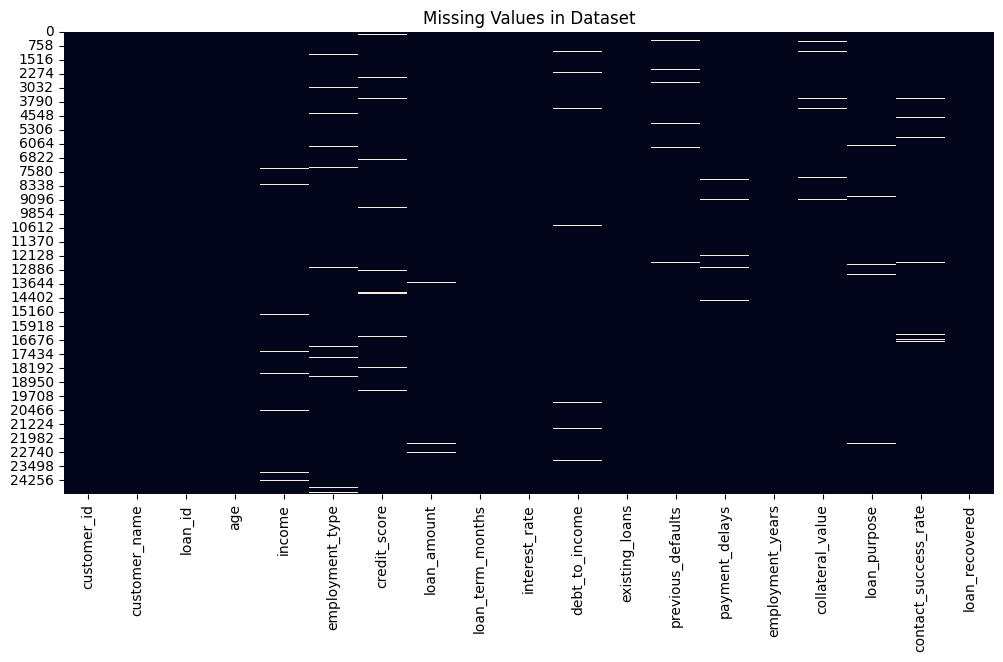

In [13]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Dataset")
plt.show()

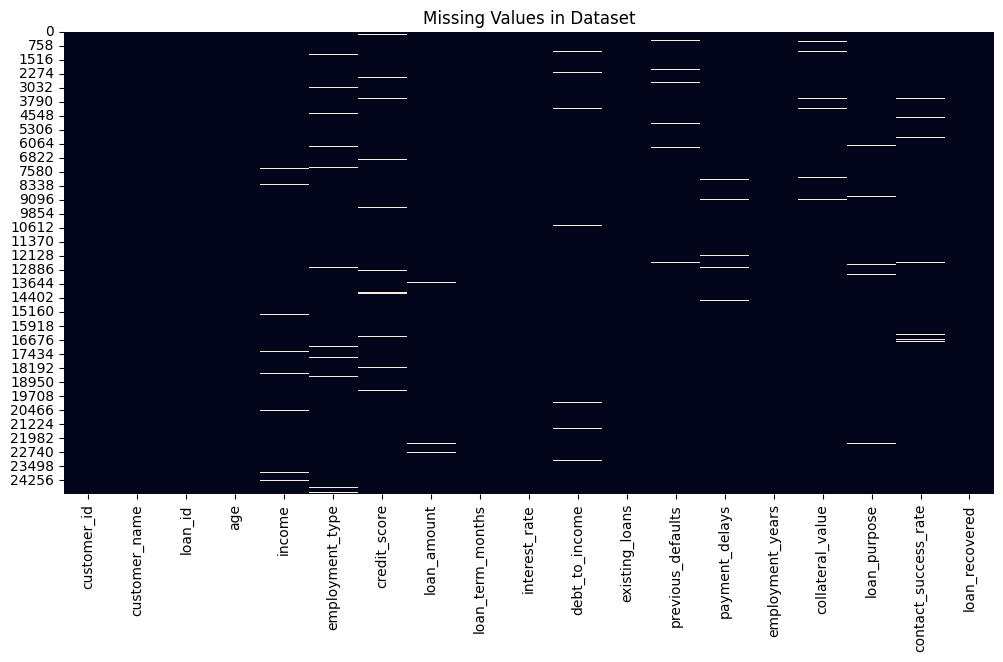

In [14]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Dataset")
plt.show()

In [15]:
df.duplicated().sum()

np.int64(300)

In [16]:
df["employment_type"].value_counts(dropna=False)

employment_type
Salaried           11766
Self-employed       4935
Business            4074
Contract            2493
Unemployed          1205
NaN                  304
salaried              36
 Salaried             31
SALARIED              26
 Self-employed        24
BUSINESS              19
SELF-EMPLOYED         15
self-employed         13
business              11
CONTRACT              10
 Business             10
contract               9
unemployed             5
 Contract              5
 Unemployed            5
UNEMPLOYED             4
Name: count, dtype: int64

In [17]:
df["loan_purpose"].value_counts(dropna=False)

loan_purpose
Personal       7004
Home           5501
Vehicle        5432
Business       3627
Education      2963
NaN             251
 Home            23
 Personal        23
HOME             20
PERSONAL         20
home             20
vehicle          17
personal         15
business         14
VEHICLE          14
BUSINESS         13
 Vehicle         13
 Business         9
EDUCATION         8
education         7
 Education        6
Name: count, dtype: int64

In [18]:
df["age"].describe()

count    25000.000000
mean        37.108640
std          8.736799
min         17.000000
25%         31.000000
50%         37.000000
75%         43.000000
max         85.000000
Name: age, dtype: float64

In [19]:
df["income"].describe()

count    2.455000e+04
mean     7.391621e+04
std      5.605786e+04
min     -5.000000e+03
25%      5.050000e+04
50%      7.150000e+04
75%      9.300000e+04
max      2.500000e+06
Name: income, dtype: float64

In [20]:
df["credit_score"].describe()

count    24626.000000
mean       616.278080
std         51.590739
min        250.000000
25%        582.000000
50%        616.000000
75%        650.000000
max        950.000000
Name: credit_score, dtype: float64

In [21]:
df["credit_score"].describe()

count    24626.000000
mean       616.278080
std         51.590739
min        250.000000
25%        582.000000
50%        616.000000
75%        650.000000
max        950.000000
Name: credit_score, dtype: float64

In [22]:
df["debt_to_income"].describe()

count    24552.000000
mean         0.232568
std          0.080433
min         -0.100000
25%          0.179000
50%          0.229000
75%          0.281000
max          1.500000
Name: debt_to_income, dtype: float64

### Saving the imported data

In [23]:
import os
os.makedirs("../data", exist_ok=True)
df.to_csv("../data/01_imported_data.csv", index=False)
print("Imported data saved successfully!")


Imported data saved successfully!


### Why Recovery Prediction is Useful

In a traditional collection process, recovery teams may have limited
resources and cannot give the same level of attention to every account.

A recovery probability model can help rank accounts according to their
estimated likelihood of recovery. This can support decisions such as which
accounts require more intensive follow-up and which accounts may be handled
through regular or automated communication.

The model is intended to support collection decisions rather than replace
human judgement.

## Loan Lifecycle and Recovery Process

A loan generally moves through the following stages:

**Loan Application → Loan Approval → Loan Disbursement → Repayment → 
Payment Delays → Default / Delinquency → Collection Follow-up → 
Recovery / Non-Recovery**

For this project, the available dataset contains information about the
borrower, loan characteristics, financial condition, repayment behaviour,
and previous collection behaviour.

These factors help the model identify patterns associated with successful
or unsuccessful loan recovery.

The target variable `loan_recovered` represents the final recovery outcome:

- `1` → Loan Recovered
- `0` → Loan Not Recovered

The machine learning model uses historical information to estimate the
probability that a loan will be recovered. This probability can then be
used to prioritize debt recovery efforts.

In [24]:
print("Loan Recovery Target:")
print("1 = Recovered")
print("0 = Not Recovered")

print("\nTarget distribution:")
print(df["loan_recovered"].value_counts())

Loan Recovery Target:
1 = Recovered
0 = Not Recovered

Target distribution:
loan_recovered
1    16251
0     8749
Name: count, dtype: int64
